Load data

In [1]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TOL = 0.01

df = pd.read_parquet(ROOT / "data" / "processed" / "transactions.parquet")
meta = json.loads((ROOT / "data" / "processed" / "meta.json").read_text())
CUTOFF_STEP = int(np.floor(0.8 * meta["max_step"]))
tc = df[df["type"].isin(["TRANSFER", "CASH_OUT"])]
results = {}
print(df.shape, CUTOFF_STEP)

(6362620, 12) 594


Dataset size

In [2]:
results["dataset_size"] = {
    "max_step": int(df["step"].max()),
    "min_step": int(df["step"].min()),
    "steps_per_day": 24,
    "row_count": int(len(df)),
    "fraud_count": int(df["isFraud"].sum()),
    "fraud_rate": float(df["isFraud"].mean()),
    "cutoff_step": CUTOFF_STEP,
}
print(results["dataset_size"])

{'max_step': 743, 'min_step': 1, 'steps_per_day': 24, 'row_count': 6362620, 'fraud_count': 8213, 'fraud_rate': 0.001290820448180152, 'cutoff_step': 594}


Fraud by type

In [3]:
g = df.groupby("type", observed=True)["isFraud"].agg(["size", "sum", "mean"])
h2 = pd.DataFrame({"rows": g["size"], "fraud_count": g["sum"], "fraud_rate": g["mean"]})
results["fraud_by_type"] = {
    t: {"rows": int(r.rows), "fraud_count": int(r.fraud_count), "fraud_rate": float(r.fraud_rate)}
    for t, r in h2.iterrows()
}
h2

,rows,fraud_count,fraud_rate
type,,,
CASH_IN,1399284,0,0.000000
CASH_OUT,2237500,4116,0.001840
DEBIT,41432,0,0.000000
PAYMENT,2151495,0,0.000000
TRANSFER,532909,4097,0.007688


Balance identity by label (TRANSFER and CASH_OUT)

In [4]:
def rate_by_label(frame, mask):
    s = pd.Series(np.asarray(mask), index=frame.index)
    out = {}
    for label in (0, 1):
        sel = s[frame["isFraud"] == label]
        out[str(label)] = {"rows": int(len(sel)), "count": int(sel.sum()), "rate": float(sel.mean())}
    return out


orig_id = (tc["newbalanceOrig"] - (tc["oldbalanceOrg"] - tc["amount"])).abs() <= TOL
dest_id = (tc["newbalanceDest"] - (tc["oldbalanceDest"] + tc["amount"])).abs() <= TOL
results["balance_identity"] = {
    "population": "TRANSFER and CASH_OUT",
    "tolerance": TOL,
    "orig_identity": rate_by_label(tc, orig_id),
    "dest_identity": rate_by_label(tc, dest_id),
    "both_identity": rate_by_label(tc, orig_id & dest_id),
}
print(json.dumps(results["balance_identity"], indent=1))

{
 "population": "TRANSFER and CASH_OUT",
 "tolerance": 0.01,
 "orig_identity": {
  "0": {
   "rows": 2762196,
   "count": 262190,
   "rate": 0.09492085282869138
  },
  "1": {
   "rows": 8213,
   "count": 8168,
   "rate": 0.9945208815292829
  }
 },
 "dest_identity": {
  "0": {
   "rows": 2762196,
   "count": 2138599,
   "rate": 0.7742386854517203
  },
  "1": {
   "rows": 8213,
   "count": 3573,
   "rate": 0.4350420065749422
  }
 },
 "both_identity": {
  "0": {
   "rows": 2762196,
   "count": 209299,
   "rate": 0.07577268231508553
  },
  "1": {
   "rows": 8213,
   "count": 3554,
   "rate": 0.43272860099841715
  }
 }
}


Exact drain by label

In [5]:
def drain(frame):
    eq = (frame["amount"] - frame["oldbalanceOrg"]).abs() <= TOL
    return {
        "amount_eq_oldbalanceOrg": rate_by_label(frame, eq),
        "newbalanceOrig_eq_zero": rate_by_label(frame, frame["newbalanceOrig"] == 0),
        "exact_drain_and_zero_new": rate_by_label(frame, eq & (frame["newbalanceOrig"] == 0)),
    }


results["exact_drain"] = {
    "tolerance": TOL,
    "transfer_cash_out": drain(tc),
    "all_rows": drain(df),
}
print(json.dumps(results["exact_drain"]["transfer_cash_out"], indent=1))

{
 "amount_eq_oldbalanceOrg": {
  "0": {
   "rows": 2762196,
   "count": 1,
   "rate": 3.6203078999462746e-07
  },
  "1": {
   "rows": 8213,
   "count": 8034,
   "rate": 0.9782052843053696
  }
 },
 "newbalanceOrig_eq_zero": {
  "0": {
   "rows": 2762196,
   "count": 2488603,
   "rate": 0.9009509100729999
  },
  "1": {
   "rows": 8213,
   "count": 8053,
   "rate": 0.9805186898818946
  }
 },
 "exact_drain_and_zero_new": {
  "0": {
   "rows": 2762196,
   "count": 1,
   "rate": 3.6203078999462746e-07
  },
  "1": {
   "rows": 8213,
   "count": 8024,
   "rate": 0.9769877024229879
  }
 }
}


Destination zero pattern by label

In [6]:
def dest_zero(frame):
    mask = (frame["oldbalanceDest"] == 0) & (frame["newbalanceDest"] == 0)
    return {"oldbalanceDest_zero_and_newbalanceDest_zero": rate_by_label(frame, mask)}


is_merchant = df["nameDest"].astype(str).str.startswith("M")
results["destination_zero"] = {
    "transfer_cash_out": dest_zero(tc),
    "all_rows": dest_zero(df),
    "nameDest_starts_with_M": {
        "rows": int(is_merchant.sum()),
        "fraud_count": int(df.loc[is_merchant, "isFraud"].sum()),
    },
}
print(json.dumps(results["destination_zero"], indent=1))

{
 "transfer_cash_out": {
  "oldbalanceDest_zero_and_newbalanceDest_zero": {
   "0": {
    "rows": 2762196,
    "count": 1706,
    "rate": 0.0006176245277308345
   },
   "1": {
    "rows": 8213,
    "count": 4076,
    "rate": 0.49628637525873615
   }
  }
 },
 "all_rows": {
  "oldbalanceDest_zero_and_newbalanceDest_zero": {
   "0": {
    "rows": 6354407,
    "count": 2313206,
    "rate": 0.36403176567065976
   },
   "1": {
    "rows": 8213,
    "count": 4076,
    "rate": 0.49628637525873615
   }
  }
 },
 "nameDest_starts_with_M": {
  "rows": 2151495,
  "fraud_count": 0
 }
}


isFlaggedFraud against isFraud

In [7]:
y, f = df["isFraud"].to_numpy(), df["isFlaggedFraud"].to_numpy()
tp = int(((f == 1) & (y == 1)).sum())
fp = int(((f == 1) & (y == 0)).sum())
fn = int(((f == 0) & (y == 1)).sum())
tn = int(((f == 0) & (y == 0)).sum())
results["flagged_fraud"] = {
    "tp": tp,
    "fp": fp,
    "fn": fn,
    "tn": tn,
    "precision": tp / (tp + fp) if tp + fp else None,
    "recall": tp / (tp + fn) if tp + fn else None,
}
print(results["flagged_fraud"])

{'tp': 16, 'fp': 0, 'fn': 8197, 'tn': 6354407, 'precision': 1.0, 'recall': 0.0019481310118105442}


Fraud by step and after cutoff

In [8]:
by_step = df.groupby("step")["isFraud"].agg(["size", "sum"])
after = df[df["step"] > CUTOFF_STEP]
results["time_split"] = {
    "cutoff_step": CUTOFF_STEP,
    "fraud_by_step": {str(int(s)): int(v) for s, v in by_step["sum"].items()},
    "train_rows": int(len(df) - len(after)),
    "train_fraud_count": int(df["isFraud"].sum() - after["isFraud"].sum()),
    "test_rows": int(len(after)),
    "test_fraud_count": int(after["isFraud"].sum()),
    "test_fraud_rate": float(after["isFraud"].mean()),
}
print({k: v for k, v in results["time_split"].items() if k != "fraud_by_step"})

{'cutoff_step': 594, 'train_rows': 6239040, 'train_fraud_count': 6559, 'test_rows': 123580, 'test_fraud_count': 1654, 'test_fraud_rate': 0.01338404272536009}


Account key repetition

In [9]:
def key_stats(col):
    codes = df[col].cat.codes.to_numpy()
    counts = np.bincount(codes)
    return {
        "unique": int(len(counts)),
        "rows": int(len(codes)),
        "share_rows_key_repeats": float((counts[codes] > 1).mean()),
    }


results["account_repetition"] = {"nameOrig": key_stats("nameOrig"), "nameDest": key_stats("nameDest")}
print(json.dumps(results["account_repetition"], indent=1))

{
 "nameOrig": {
  "unique": 6353307,
  "rows": 6362620,
  "share_rows_key_repeats": 0.002925052887018241
 },
 "nameDest": {
  "unique": 2722362,
  "rows": 6362620,
  "share_rows_key_repeats": 0.644375430247288
 }
}


Write eda_numbers.json

In [10]:
(ROOT / "reports" / "eda_numbers.json").write_text(json.dumps(results, indent=2) + "\n")
print(sorted(results))

['dataset_size', 'fraud_by_type', 'balance_identity', 'exact_drain', 'destination_zero', 'flagged_fraud', 'time_split', 'account_repetition']


Figure 1: fraud by type

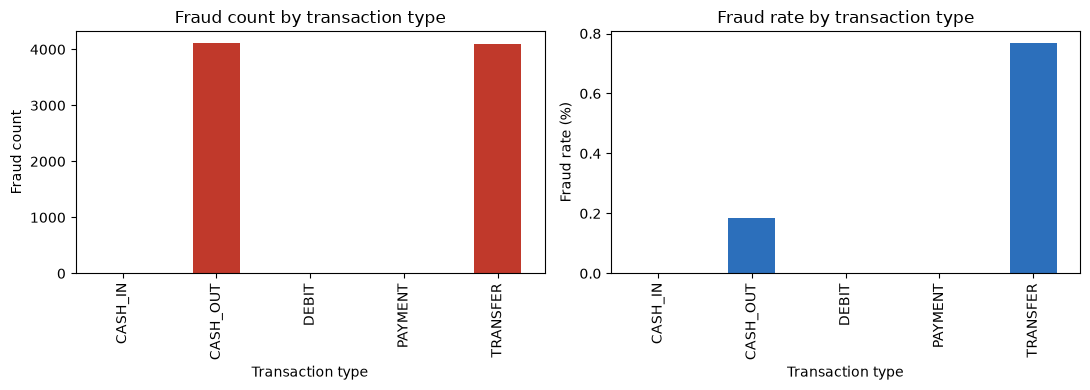

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
h2["fraud_count"].plot.bar(ax=ax[0], color="#c0392b")
ax[0].set_title("Fraud count by transaction type")
ax[0].set_xlabel("Transaction type")
ax[0].set_ylabel("Fraud count")
(h2["fraud_rate"] * 100).plot.bar(ax=ax[1], color="#2c6fbb")
ax[1].set_title("Fraud rate by transaction type")
ax[1].set_xlabel("Transaction type")
ax[1].set_ylabel("Fraud rate (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fraud_by_type.png", dpi=150)
plt.show()
plt.close(fig)

Figure 2: fraud per step

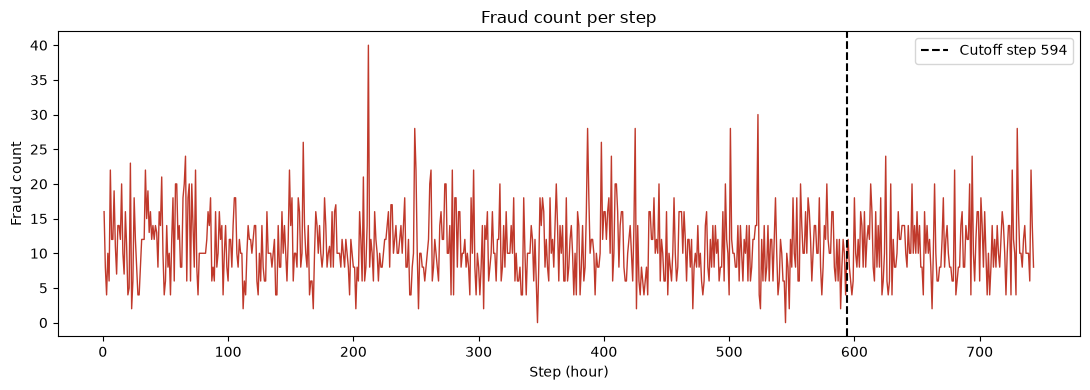

In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(by_step.index, by_step["sum"], color="#c0392b", linewidth=1)
ax.axvline(CUTOFF_STEP, color="black", linestyle="--", label=f"Cutoff step {CUTOFF_STEP}")
ax.set_title("Fraud count per step")
ax.set_xlabel("Step (hour)")
ax.set_ylabel("Fraud count")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "fraud_per_step.png", dpi=150)
plt.show()
plt.close(fig)

Figure 3: fraud rate per hour of day

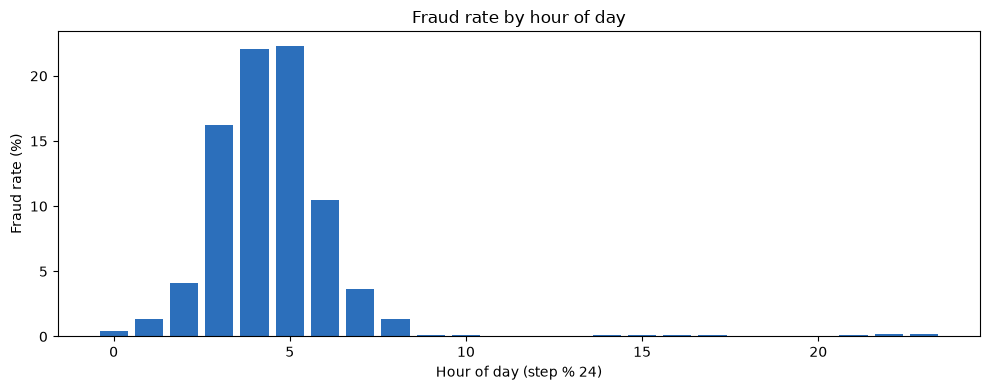

In [13]:
hod = (df["step"] % 24).rename("hour_of_day")
rate_hod = df.groupby(hod)["isFraud"].mean() * 100
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(rate_hod.index, rate_hod.values, color="#2c6fbb")
ax.set_title("Fraud rate by hour of day")
ax.set_xlabel("Hour of day (step % 24)")
ax.set_ylabel("Fraud rate (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fraud_rate_by_hour.png", dpi=150)
plt.show()
plt.close(fig)

Figure 4: amount distribution by label

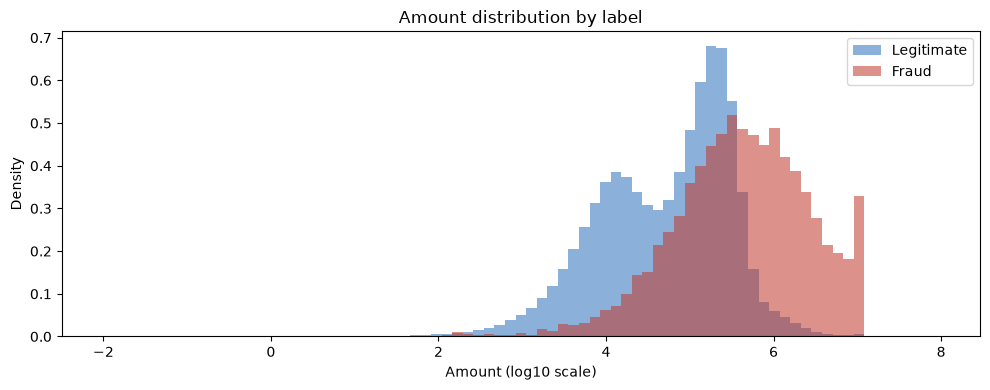

In [14]:
pos = df[df["amount"] > 0]
bins = np.linspace(np.log10(pos["amount"].min()), np.log10(pos["amount"].max()), 80)
fig, ax = plt.subplots(figsize=(10, 4))
for label, color, name in ((0, "#2c6fbb", "Legitimate"), (1, "#c0392b", "Fraud")):
    vals = np.log10(pos.loc[pos["isFraud"] == label, "amount"])
    ax.hist(vals, bins=bins, density=True, alpha=0.55, color=color, label=name)
ax.set_title("Amount distribution by label")
ax.set_xlabel("Amount (log10 scale)")
ax.set_ylabel("Density")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "amount_by_label.png", dpi=150)
plt.show()
plt.close(fig)

Figure 5: balance evidence by label

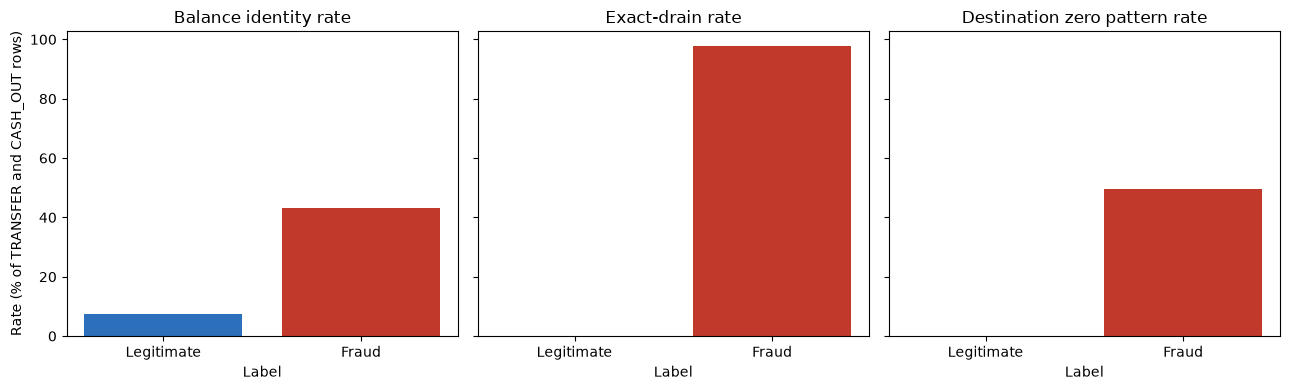

In [15]:
panels = [
    ("Balance identity rate", results["balance_identity"]["both_identity"]),
    ("Exact-drain rate", results["exact_drain"]["transfer_cash_out"]["amount_eq_oldbalanceOrg"]),
    (
        "Destination zero pattern rate",
        results["destination_zero"]["transfer_cash_out"]["oldbalanceDest_zero_and_newbalanceDest_zero"],
    ),
]
fig, ax = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for a, (title, d) in zip(ax, panels):
    a.bar(["Legitimate", "Fraud"], [d["0"]["rate"] * 100, d["1"]["rate"] * 100], color=["#2c6fbb", "#c0392b"])
    a.set_title(title)
    a.set_xlabel("Label")
ax[0].set_ylabel("Rate (% of TRANSFER and CASH_OUT rows)")
fig.tight_layout()
fig.savefig(FIG_DIR / "balance_evidence_by_label.png", dpi=150)
plt.show()
plt.close(fig)